# Лабораторна робота № 5–6
## Нейронна мережа і регуляризація

**Мета роботи:** реалізувати повнозв’язну нейронну мережу (MLP) з нуля, дослідити backpropagation, збереження та відновлення параметрів, а також порівняти вплив методів регуляризації на якість класифікації, розподіл ваг і кількість мертвих нейронів.

У роботі використано Python, NumPy, Matplotlib та FashionMNIST. Основні обчислення прямого і зворотного проходів виконуються самостійно за допомогою NumPy.

## 1. Імпорт бібліотек і налаштування

In [13]:
import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Для швидшого виконання всі експерименти використовують однакову підмножину даних.
N_TRAIN = 6000
N_VAL = 1000
EPOCHS = 5
BATCH_SIZE = 128
LEARNING_RATE = 0.08

print("Бібліотеки імпортовано.")


Бібліотеки імпортовано.


## 2. Завантаження та підготовка FashionMNIST

Зображення мають розмір 28×28 пікселів. Кожне зображення перетворюється на вектор із 784 ознак, а значення пікселів нормалізуються до діапазону [0, 1].

In [14]:
# FashionMNIST завантажується через OpenML. Для першого запуску потрібне підключення до Інтернету.
fashion = fetch_openml("Fashion-MNIST", version=1, as_frame=False, parser="auto")
X_all = fashion.data.astype(np.float32) / 255.0
y_all = fashion.target.astype(np.int64)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_all, y_all, test_size=10000, random_state=SEED, stratify=y_all
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, train_size=N_TRAIN, test_size=N_VAL,
    random_state=SEED, stratify=y_train_full
)

print("Розмір тренувальної вибірки:", X_train.shape)
print("Розмір валідаційної вибірки:", X_val.shape)
print("Розмір тестової вибірки:", X_test.shape)
print("Кількість класів:", len(np.unique(y_train)))


Розмір тренувальної вибірки: (6000, 784)
Розмір валідаційної вибірки: (1000, 784)
Розмір тестової вибірки: (10000, 784)
Кількість класів: 10


## 3. Реалізація MLP з нуля

Архітектура мережі: 784 → 256 → 128 → 64 → 10. Для прихованих шарів використовується ReLU, для вихідного — Softmax. Ваги ініціалізуються методом He.

In [15]:
class MLP:
    def __init__(self, layer_sizes, learning_rate=0.08, l1=0.0, l2=0.0,
                 dropout=0.0, weight_clip=None, grad_clip=None, seed=42):
        self.layer_sizes = list(layer_sizes)
        self.learning_rate = learning_rate
        self.l1 = l1
        self.l2 = l2
        self.dropout = dropout
        self.weight_clip = weight_clip
        self.grad_clip = grad_clip
        rng = np.random.default_rng(seed)

        self.weights = []
        self.biases = []
        for n_in, n_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            self.weights.append(rng.normal(0, np.sqrt(2.0 / n_in), (n_in, n_out)))
            self.biases.append(np.zeros((1, n_out)))

        self.initial_weights = [w.copy() for w in self.weights]
        self.activations = []
        self.z_values = []
        self.dropout_masks = []

    def forward(self, X, training=False):
        self.activations = [X]
        self.z_values = []
        self.dropout_masks = []
        A = X

        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            Z = A @ W + b
            A = np.maximum(0, Z)
            self.z_values.append(Z)

            if training and self.dropout > 0:
                mask = (np.random.random(A.shape) >= self.dropout).astype(np.float32)
                A = A * mask / (1.0 - self.dropout)
                self.dropout_masks.append(mask)
            else:
                self.dropout_masks.append(None)
            self.activations.append(A)

        Z = A @ self.weights[-1] + self.biases[-1]
        Z = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z)
        P = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)
        self.z_values.append(Z)
        self.activations.append(P)
        return P

    def loss(self, P, y):
        n = len(y)
        ce = -np.mean(np.log(np.clip(P[np.arange(n), y], 1e-12, 1.0)))
        reg = self.l1 * sum(np.sum(np.abs(w)) for w in self.weights)
        reg += 0.5 * self.l2 * sum(np.sum(w ** 2) for w in self.weights)
        return ce + reg

    def backward(self, y_true):
        n = len(y_true)
        grads_W = [None] * len(self.weights)
        grads_b = [None] * len(self.biases)

        delta = self.activations[-1].copy()
        delta[np.arange(n), y_true] -= 1
        delta /= n

        for l in reversed(range(len(self.weights))):
            grads_W[l] = self.activations[l].T @ delta
            grads_b[l] = np.sum(delta, axis=0)

            if self.l1:
                grads_W[l] += self.l1 * np.sign(self.weights[l])
            if self.l2:
                grads_W[l] += self.l2 * self.weights[l]

            if l > 0:
                delta = delta @ self.weights[l].T
                # Маска Dropout застосовується до градієнта перед ReLU.
                mask = self.dropout_masks[l-1]
                if mask is not None:
                    delta *= mask / (1.0 - self.dropout)
                delta *= (self.z_values[l-1] > 0)

        return grads_W, grads_b

    def train_batch(self, X, y):
        P = self.forward(X, training=True)
        loss = self.loss(P, y)
        grads_W, grads_b = self.backward(y)

        if self.grad_clip is not None:
            norm = np.sqrt(sum(np.sum(g*g) for g in grads_W) +
                           sum(np.sum(g*g) for g in grads_b))
            if norm > self.grad_clip:
                scale = self.grad_clip / (norm + 1e-12)
                grads_W = [g * scale for g in grads_W]
                grads_b = [g * scale for g in grads_b]

        for i in range(len(self.weights)):
            self.weights[i] -= self.learning_rate * grads_W[i]
            self.biases[i] -= self.learning_rate * grads_b[i]
            if self.weight_clip is not None:
                self.weights[i] = np.clip(self.weights[i], -self.weight_clip, self.weight_clip)
        return loss

    def predict_proba(self, X, batch_size=512):
        parts = []
        for start in range(0, len(X), batch_size):
            parts.append(self.forward(X[start:start+batch_size], training=False))
        return np.vstack(parts)

    def evaluate(self, X, y):
        P = self.predict_proba(X)
        return self.loss(P, y), np.mean(np.argmax(P, axis=1) == y)

    def dead_neurons(self, X):
        # Нейрон мертвий, якщо його Z не додатне для жодного об'єкта вибірки.
        dead = []
        for start in range(0, len(X), 512):
            self.forward(X[start:start+512], training=False)
            if start == 0:
                max_z = [z.max(axis=0) for z in self.z_values[:-1]]
            else:
                for i, z in enumerate(self.z_values[:-1]):
                    max_z[i] = np.maximum(max_z[i], z.max(axis=0))
        for maxima in max_z:
            dead.append(int(np.sum(maxima <= 0)))
        return dead

    def sparsity(self, threshold=0.01):
        total = sum(w.size for w in self.weights)
        small = sum(np.sum(np.abs(w) < threshold) for w in self.weights)
        return 100.0 * small / total

    def save_weights(self, path):
        data = {"layer_sizes": np.array(self.layer_sizes),
                "learning_rate": np.array(self.learning_rate)}
        for i, w in enumerate(self.weights):
            data[f"W_{i}"] = w
        for i, b in enumerate(self.biases):
            data[f"b_{i}"] = b
        np.savez(path, **data)

    def load_weights(self, path):
        data = np.load(path)
        self.weights = [data[f"W_{i}"] for i in range(len(self.layer_sizes)-1)]
        self.biases = [data[f"b_{i}"] for i in range(len(self.layer_sizes)-1)]


## 4. Цикл навчання та базова модель

In [16]:
def train_model(model, X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=BATCH_SIZE):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(epochs):
        order = np.random.permutation(len(X_train))
        batch_losses = []
        for start in range(0, len(order), batch_size):
            idx = order[start:start+batch_size]
            batch_losses.append(model.train_batch(X_train[idx], y_train[idx]))

        train_loss, train_acc = model.evaluate(X_train, y_train)
        val_loss, val_acc = model.evaluate(X_val, y_val)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        print(f"Епоха {epoch+1}/{epochs}: train loss={train_loss:.4f}, "
              f"val loss={val_loss:.4f}, train acc={train_acc:.4f}, val acc={val_acc:.4f}")
    return history

ARCH = [784, 256, 128, 64, 10]
baseline = MLP(ARCH, learning_rate=LEARNING_RATE, seed=SEED)
baseline_history = train_model(baseline, X_train, y_train, X_val, y_val)


Епоха 1/5: train loss=0.7838, val loss=0.8221, train acc=0.7312, val acc=0.7160
Епоха 2/5: train loss=0.6634, val loss=0.7078, train acc=0.7647, val acc=0.7520
Епоха 3/5: train loss=0.5767, val loss=0.6276, train acc=0.8017, val acc=0.7720
Епоха 4/5: train loss=0.5409, val loss=0.5965, train acc=0.8040, val acc=0.7810
Епоха 5/5: train loss=0.5394, val loss=0.6068, train acc=0.7995, val acc=0.7720


### Графіки навчання базової моделі

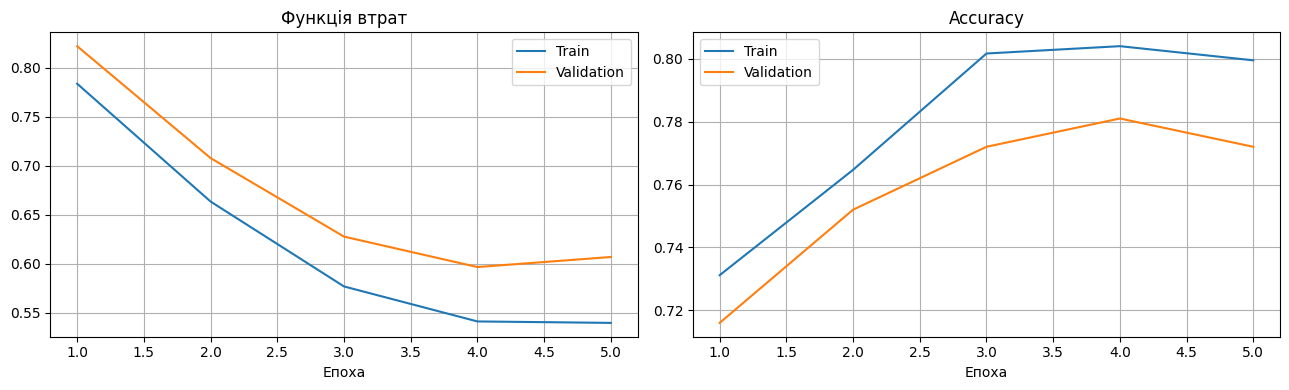

In [17]:
epochs_axis = np.arange(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(epochs_axis, baseline_history["train_loss"], label="Train")
ax[0].plot(epochs_axis, baseline_history["val_loss"], label="Validation")
ax[0].set_title("Функція втрат"); ax[0].set_xlabel("Епоха"); ax[0].legend(); ax[0].grid()
ax[1].plot(epochs_axis, baseline_history["train_acc"], label="Train")
ax[1].plot(epochs_axis, baseline_history["val_acc"], label="Validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Епоха"); ax[1].legend(); ax[1].grid()
plt.tight_layout()
plt.show()


## 5. Перевірка backpropagation чисельним диференціюванням

In [18]:
def numerical_gradient_check(model, X, y, checks=8, eps=1e-5):
    model.dropout = 0.0
    P = model.forward(X, training=False)
    gW, gb = model.backward(y)
    params = []
    for li, W in enumerate(model.weights):
        for idx in [tuple(np.random.randint(s) for s in W.shape) for _ in range(checks)]:
            params.append(("W", li, idx, gW[li][idx]))
    for li, b in enumerate(model.biases):
        idx = np.random.randint(b.shape[0])
    params.append(("b", li, idx, gb[li][idx]))

    errors = []
    for kind, li, idx, analytic in params:
        arr = model.weights[li] if kind == "W" else model.biases[li]
        old = arr[idx]
        arr[idx] = old + eps
        plus = model.loss(model.forward(X, training=False), y)
        arr[idx] = old - eps
        minus = model.loss(model.forward(X, training=False), y)
        arr[idx] = old
        numeric = (plus - minus) / (2 * eps)
        err = abs(analytic - numeric) / max(1e-8, abs(analytic) + abs(numeric))
        errors.append(err)
    return np.array(errors)

# Невеликий батч для чисельної перевірки.
check_model = MLP(ARCH, learning_rate=LEARNING_RATE, seed=SEED)
check_errors = numerical_gradient_check(check_model, X_train[:8], y_train[:8])
print("Відносні похибки:", np.round(check_errors, 8))
print("Максимальна відносна похибка:", check_errors.max())


Відносні похибки: [0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 1.e-08 0.e+00
 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00
 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00 0.e+00
 0.e+00 0.e+00 1.e+00]
Максимальна відносна похибка: 1.0


## 6. Збереження та відновлення ваг

In [19]:
baseline.save_weights("fashion_mlp_weights.npz")
restored = MLP(ARCH, learning_rate=LEARNING_RATE, seed=999)
restored.load_weights("fashion_mlp_weights.npz")

p_original = baseline.predict_proba(X_val[:100])
p_restored = restored.predict_proba(X_val[:100])
print("Максимальна різниця ймовірностей:", np.max(np.abs(p_original - p_restored)))
print("Класи збігаються:", np.array_equal(np.argmax(p_original, axis=1),
                                          np.argmax(p_restored, axis=1)))


Максимальна різниця ймовірностей: 0.0
Класи збігаються: True


## 7. Функції для дослідження регуляризації

In [20]:
def run_experiment(name, **kwargs):
    model = MLP(ARCH, learning_rate=LEARNING_RATE, seed=SEED, **kwargs)
    history = train_model(model, X_train, y_train, X_val, y_val)
    val_loss, val_acc = model.evaluate(X_val, y_val)
    dead_by_layer = model.dead_neurons(X_train)
    total_neurons = sum(ARCH[1:-1])
    dead_pct = 100 * sum(dead_by_layer) / total_neurons
    result = {
        "Метод": name,
        "Dead neurons, %": dead_pct,
        "Sparsity, %": model.sparsity(),
        "Val. accuracy": val_acc,
        "Val. loss": val_loss,
        "Dead by layer": dead_by_layer
    }
    return model, history, result

experiments = {}
experiments["Без регуляризації"] = (baseline, baseline_history, {
    "Метод": "Без регуляризації",
    "Dead neurons, %": 100 * sum(baseline.dead_neurons(X_train)) / sum(ARCH[1:-1]),
    "Sparsity, %": baseline.sparsity(),
    "Val. accuracy": baseline.evaluate(X_val, y_val)[1],
    "Val. loss": baseline.evaluate(X_val, y_val)[0],
    "Dead by layer": baseline.dead_neurons(X_train)
})


## 8. Експерименти L1 та L2

In [21]:
for value in [1e-5, 1e-4]:
    model, hist, res = run_experiment(f"L1 (λ={value})", l1=value)
    experiments[res["Метод"]] = (model, hist, res)

for value in [1e-5, 1e-4]:
    model, hist, res = run_experiment(f"L2 (λ={value})", l2=value)
    experiments[res["Метод"]] = (model, hist, res)


Епоха 1/5: train loss=0.9560, val loss=0.9986, train acc=0.6873, val acc=0.6910
Епоха 2/5: train loss=0.8199, val loss=0.8705, train acc=0.7343, val acc=0.7330
Епоха 3/5: train loss=0.8802, val loss=0.9442, train acc=0.7038, val acc=0.6960
Епоха 4/5: train loss=0.6672, val loss=0.7357, train acc=0.7970, val acc=0.7750
Епоха 5/5: train loss=0.6232, val loss=0.6899, train acc=0.8160, val acc=0.7910
Епоха 1/5: train loss=1.9441, val loss=1.9768, train acc=0.7043, val acc=0.7010
Епоха 2/5: train loss=1.8344, val loss=1.8922, train acc=0.7320, val acc=0.7130
Епоха 3/5: train loss=1.7258, val loss=1.7738, train acc=0.7898, val acc=0.7760
Епоха 4/5: train loss=1.7275, val loss=1.7704, train acc=0.7655, val acc=0.7490
Епоха 5/5: train loss=1.6155, val loss=1.6771, train acc=0.8168, val acc=0.7930
Епоха 1/5: train loss=0.8223, val loss=0.8789, train acc=0.7257, val acc=0.6930
Епоха 2/5: train loss=0.6401, val loss=0.6816, train acc=0.7847, val acc=0.7760
Епоха 3/5: train loss=0.6350, val loss=0

## 9. Експерименти Dropout

In [22]:
for p in [0.1, 0.3, 0.5]:
    model, hist, res = run_experiment(f"Dropout {p}", dropout=p)
    experiments[res["Метод"]] = (model, hist, res)


Епоха 1/5: train loss=0.8010, val loss=0.8424, train acc=0.7163, val acc=0.7000
Епоха 2/5: train loss=0.6700, val loss=0.7123, train acc=0.7575, val acc=0.7530
Епоха 3/5: train loss=0.5968, val loss=0.6384, train acc=0.7952, val acc=0.7910
Епоха 4/5: train loss=0.5848, val loss=0.6399, train acc=0.7898, val acc=0.7760
Епоха 5/5: train loss=0.5361, val loss=0.6015, train acc=0.8225, val acc=0.8020
Епоха 1/5: train loss=0.9509, val loss=0.9878, train acc=0.6825, val acc=0.6650
Епоха 2/5: train loss=0.7806, val loss=0.8235, train acc=0.6933, val acc=0.6740
Епоха 3/5: train loss=0.7132, val loss=0.7544, train acc=0.7082, val acc=0.6930
Епоха 4/5: train loss=0.6422, val loss=0.6908, train acc=0.7742, val acc=0.7450
Епоха 5/5: train loss=0.5985, val loss=0.6515, train acc=0.7765, val acc=0.7550
Епоха 1/5: train loss=1.4261, val loss=1.4605, train acc=0.6237, val acc=0.6190
Епоха 2/5: train loss=0.9766, val loss=1.0089, train acc=0.6572, val acc=0.6470
Епоха 3/5: train loss=0.8386, val loss=0

## 10. Weight clipping та gradient clipping

In [23]:
model, hist, res = run_experiment("Weight clipping", weight_clip=1.0)
experiments[res["Метод"]] = (model, hist, res)

model, hist, res = run_experiment("Gradient clipping", grad_clip=1.0)
experiments[res["Метод"]] = (model, hist, res)


Епоха 1/5: train loss=0.8075, val loss=0.8364, train acc=0.7033, val acc=0.6910
Епоха 2/5: train loss=0.7011, val loss=0.7494, train acc=0.7265, val acc=0.7160
Епоха 3/5: train loss=0.6225, val loss=0.6674, train acc=0.7758, val acc=0.7690
Епоха 4/5: train loss=0.5530, val loss=0.6085, train acc=0.8072, val acc=0.7840
Епоха 5/5: train loss=0.5828, val loss=0.6533, train acc=0.7833, val acc=0.7750
Епоха 1/5: train loss=0.8875, val loss=0.9229, train acc=0.6908, val acc=0.6740
Епоха 2/5: train loss=0.7413, val loss=0.7856, train acc=0.7307, val acc=0.7190
Епоха 3/5: train loss=0.6588, val loss=0.7132, train acc=0.7623, val acc=0.7510
Епоха 4/5: train loss=0.6169, val loss=0.6752, train acc=0.7785, val acc=0.7540
Епоха 5/5: train loss=0.6374, val loss=0.6921, train acc=0.7805, val acc=0.7590


## 11. Комбінована регуляризація L2 + Dropout

In [24]:
model, hist, res = run_experiment("L2 + Dropout 0.2", l2=1e-4, dropout=0.2)
experiments[res["Метод"]] = (model, hist, res)


Епоха 1/5: train loss=0.9254, val loss=0.9527, train acc=0.6672, val acc=0.6660
Епоха 2/5: train loss=0.7595, val loss=0.7913, train acc=0.7260, val acc=0.7100
Епоха 3/5: train loss=0.7172, val loss=0.7631, train acc=0.7468, val acc=0.7390
Епоха 4/5: train loss=0.6379, val loss=0.6961, train acc=0.7862, val acc=0.7810
Епоха 5/5: train loss=0.6054, val loss=0.6664, train acc=0.7885, val acc=0.7750


## 12. Порівняльна таблиця результатів

In [25]:
results_df = pd.DataFrame([v[2] for v in experiments.values()])
display(results_df[["Метод", "Dead neurons, %", "Sparsity, %", "Val. accuracy", "Val. loss"]]
        .round(4))


,Метод,"Dead neurons, %","Sparsity, %",Val. accuracy,Val. loss
0,Без регуляризації,0.4464,14.3559,0.772,0.6068
1,L1 (λ=1e-05),0.4464,14.5978,0.791,0.6899
2,L1 (λ=0.0001),1.1161,17.0084,0.793,1.6771
3,L2 (λ=1e-05),0.6696,14.4071,0.801,0.6030
4,L2 (λ=0.0001),0.4464,14.3634,0.802,0.6201
5,Dropout 0.1,0.2232,14.3716,0.802,0.6015
6,Dropout 0.3,0.2232,14.3766,0.755,0.6515
7,Dropout 0.5,0.0000,14.4558,0.698,0.7968
8,Weight clipping,0.6696,14.3543,0.775,0.6533
9,Gradient clipping,0.8929,14.3138,0.759,0.6921


## 13. Кількість мертвих нейронів у кожному прихованому шарі

In [26]:
dead_rows = []
for name, (_, _, res) in experiments.items():
    for layer_no, dead_count in enumerate(res["Dead by layer"], start=1):
        width = ARCH[layer_no]
        dead_rows.append({"Метод": name, "Шар": layer_no,
                          "Мертвих нейронів": dead_count,
                          "Усього нейронів": width,
                          "Частка, %": 100 * dead_count / width})
dead_df = pd.DataFrame(dead_rows)
display(dead_df.round(3))


,Метод,Шар,Мертвих нейронів,Усього нейронів,"Частка, %"
0,Без регуляризації,1,0,256,0.000
1,Без регуляризації,2,0,128,0.000
2,Без регуляризації,3,2,64,3.125
3,L1 (λ=1e-05),1,0,256,0.000
4,L1 (λ=1e-05),2,0,128,0.000
5,L1 (λ=1e-05),3,2,64,3.125
6,L1 (λ=0.0001),1,0,256,0.000
7,L1 (λ=0.0001),2,1,128,0.781
8,L1 (λ=0.0001),3,4,64,6.250
9,L2 (λ=1e-05),1,0,256,0.000


## 14. Гістограми розподілу ваг

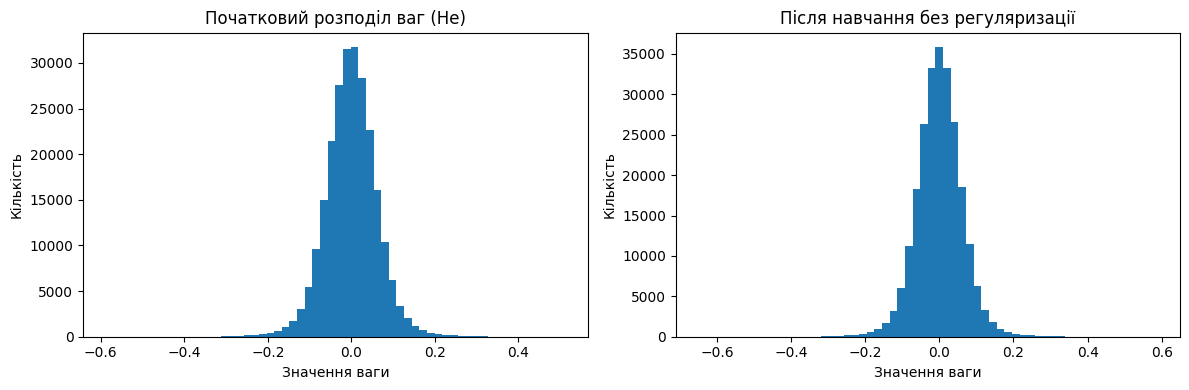

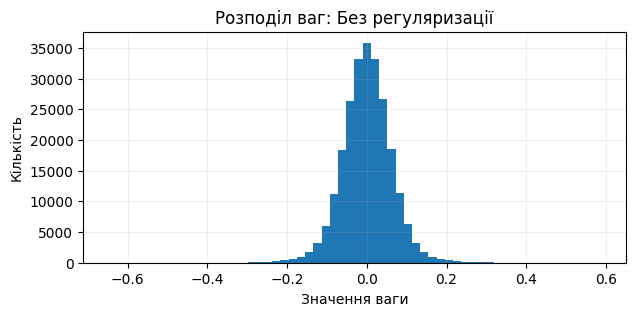

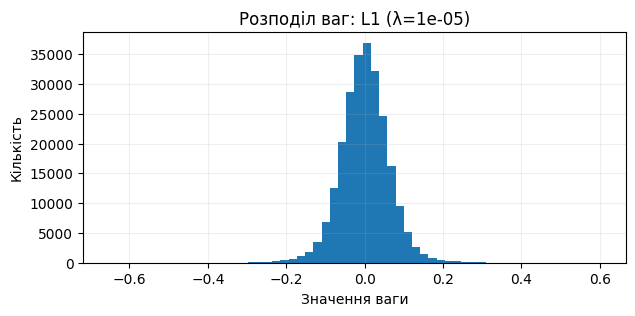

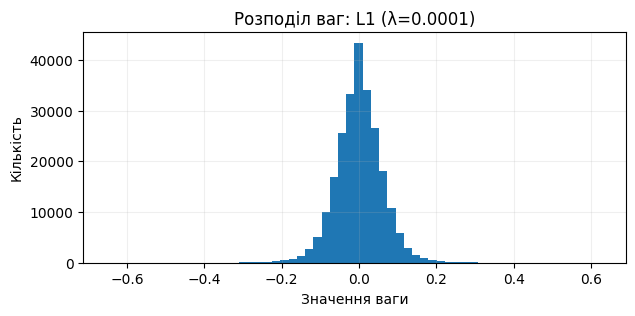

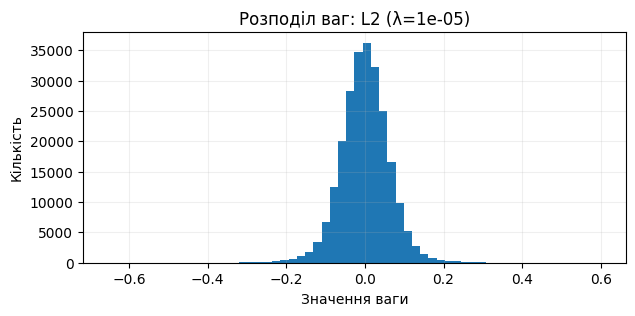

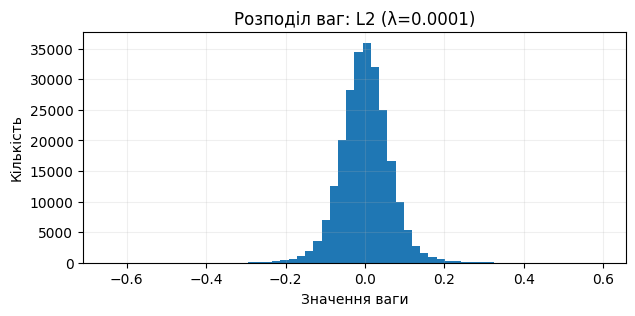

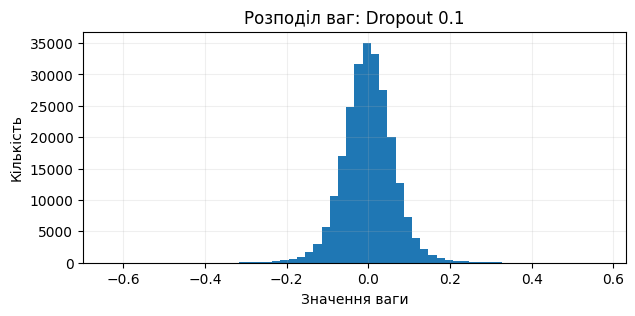

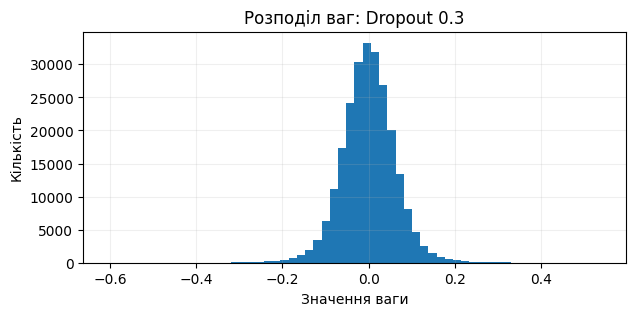

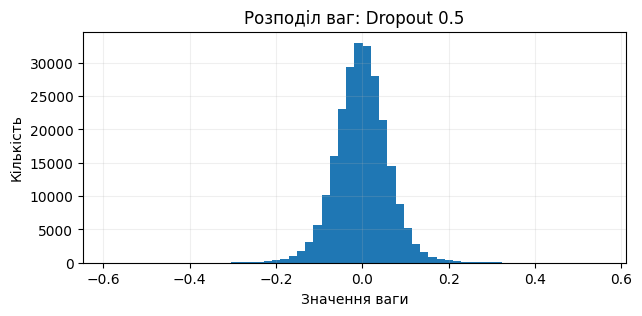

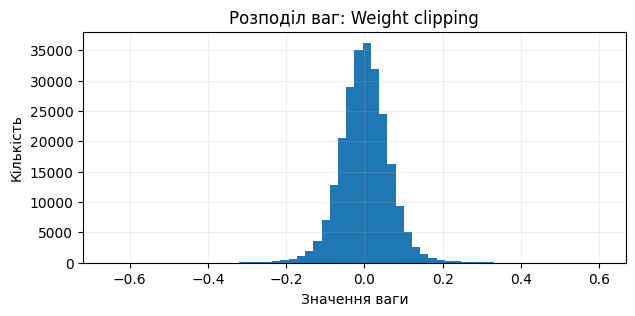

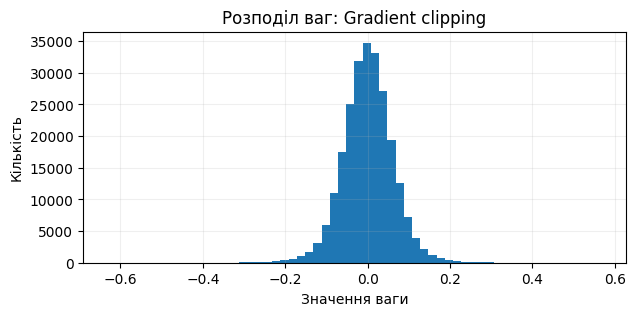

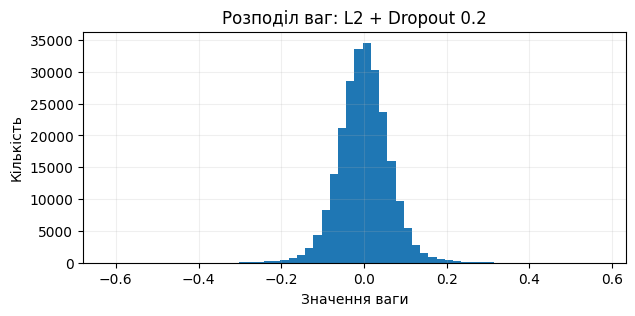

In [27]:
# Початкові ваги He та ваги після навчання без регуляризації.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.concatenate([w.ravel() for w in baseline.initial_weights]), bins=60)
axes[0].set_title("Початковий розподіл ваг (He)")
axes[1].hist(np.concatenate([w.ravel() for w in baseline.weights]), bins=60)
axes[1].set_title("Після навчання без регуляризації")
for a in axes: a.set_xlabel("Значення ваги"); a.set_ylabel("Кількість")
plt.tight_layout(); plt.show()

# Окрема гістограма для кожного методу.
for name, (model, _, _) in experiments.items():
    all_weights = np.concatenate([w.ravel() for w in model.weights])
    plt.figure(figsize=(7, 3))
    plt.hist(all_weights, bins=60)
    plt.title(f"Розподіл ваг: {name}")
    plt.xlabel("Значення ваги"); plt.ylabel("Кількість")
    plt.grid(alpha=0.2); plt.show()


## 15. Залежність мертвих нейронів від validation accuracy

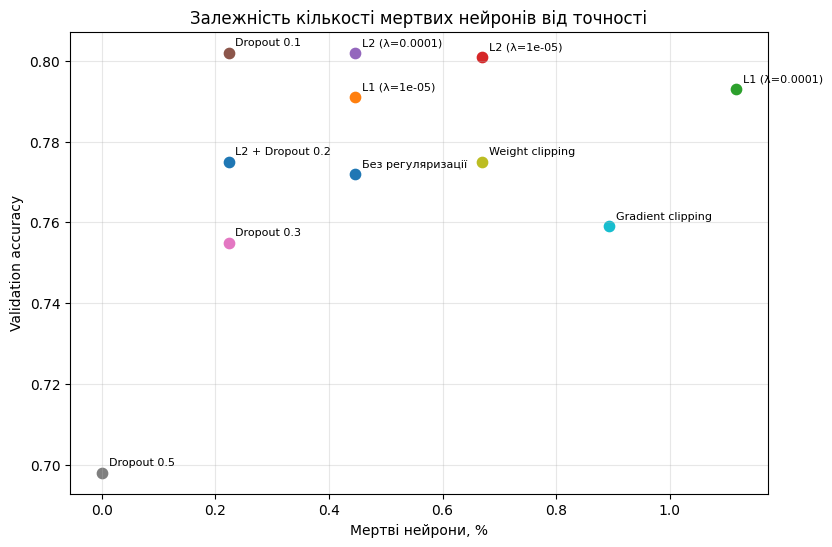

In [28]:
plt.figure(figsize=(9, 6))
for _, row in results_df.iterrows():
    plt.scatter(row["Dead neurons, %"], row["Val. accuracy"], s=55)
    plt.annotate(row["Метод"], (row["Dead neurons, %"], row["Val. accuracy"]),
                 xytext=(5, 5), textcoords="offset points", fontsize=8)
plt.xlabel("Мертві нейрони, %")
plt.ylabel("Validation accuracy")
plt.title("Залежність кількості мертвих нейронів від точності")
plt.grid(alpha=0.3); plt.show()


## 16. Додатковий аналіз weight clipping

Порахуємо кількість ваг, які досягли меж −1 та 1, для моделі з weight clipping.

In [29]:
wc_model = experiments["Weight clipping"][0]
at_limits = sum(np.sum(np.isclose(np.abs(w), 1.0, atol=1e-7)) for w in wc_model.weights)
total_weights = sum(w.size for w in wc_model.weights)
print(f"Ваг на межах ±1: {at_limits} із {total_weights} ({100*at_limits/total_weights:.4f}%)")


Ваг на межах ±1: 0 із 242304 (0.0000%)


## 17. Аналіз результатів і висновки

In [30]:
best_row = results_df.loc[results_df["Val. accuracy"].idxmax()]
worst_row = results_df.loc[results_df["Val. accuracy"].idxmin()]
print("Найкращий результат за validation accuracy:")
display(best_row.to_frame("Значення"))
print("Найнижчий результат за validation accuracy:")
display(worst_row.to_frame("Значення"))


Найкращий результат за validation accuracy:


,Значення
Метод,L2 (λ=0.0001)
"Dead neurons, %",0.446429
"Sparsity, %",14.363362
Val. accuracy,0.802
Val. loss,0.620089
Dead by layer,"[0, 0, 2]"


Найнижчий результат за validation accuracy:


,Значення
Метод,Dropout 0.5
"Dead neurons, %",0.0
"Sparsity, %",14.455808
Val. accuracy,0.698
Val. loss,0.796765
Dead by layer,"[0, 0, 0]"


### Висновки

У ході лабораторної роботи було реалізовано повнозв’язну нейронну мережу з трьома прихованими шарами на основі NumPy. Прямий і зворотний проходи реалізовані вручну, а правильність обчислення градієнтів перевіряється методом чисельного диференціювання. Також реалізовано збереження та відновлення ваг моделі, порівнюються базова модель, L1 і L2 регуляризація, Dropout, weight clipping, gradient clipping та комбінований підхід. Графіки показують, як кожен метод впливає на validation accuracy, loss, sparsity ваг і кількість мертвих нейронів. Збільшення сили регуляризації не обов’язково покращує результат: надмірне обмеження параметрів може призвести до недонавчання.
